<a href="https://colab.research.google.com/github/Dharani-001/Language_Identification_LSTM/blob/main/Language_Identification_LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files

uploaded = files.upload()

Saving dataset.csv to dataset.csv


In [8]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import pad_sequences

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [7]:
df = pd.read_csv("dataset.csv")

print(df.head())
print(df.shape)
print(df.columns)
print(df.isnull().sum())

                                                Text  language
0  klement gottwaldi surnukeha palsameeriti ning ...  Estonian
1  sebes joseph pereira thomas  på eng the jesuit...   Swedish
2  ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...      Thai
3  விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...     Tamil
4  de spons behoort tot het geslacht haliclona en...     Dutch
(22000, 2)
Index(['Text', 'language'], dtype='object')
Text        0
language    0
dtype: int64


In [9]:
import pandas as pd
import re

df = df[["Text", "language"]].copy()

df.columns = ["text", "language"]

df = df.dropna()

df["text"] = df["text"].astype(str).str.strip()
df["language"] = df["language"].astype(str).str.strip()

df = df[
    (df["text"] != "") &
    (df["language"] != "")
]

df = df.drop_duplicates(subset=["text", "language"])

print(df.head())
print("Dataset shape:", df.shape)
print("Number of languages:", df["language"].nunique())
print(df["language"].value_counts())

                                                text  language
0  klement gottwaldi surnukeha palsameeriti ning ...  Estonian
1  sebes joseph pereira thomas  på eng the jesuit...   Swedish
2  ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...      Thai
3  விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...     Tamil
4  de spons behoort tot het geslacht haliclona en...     Dutch
Dataset shape: (21858, 2)
Number of languages: 22
language
Japanese      1000
Thai          1000
Korean        1000
Chinese       1000
Urdu          1000
Turkish       1000
Romanian      1000
English       1000
Persian       1000
Estonian       999
Russian        999
Arabic         998
Portugese      997
Spanish        996
Dutch          995
Pushto         993
Swedish        992
French         990
Hindi          990
Tamil          981
Indonesian     975
Latin          953
Name: count, dtype: int64


In [10]:
selected_languages = df["language"].value_counts().head(10).index

df = df[df["language"].isin(selected_languages)]

df = (
    df.groupby("language", group_keys=False)
      .sample(n=500, random_state=42)
      .reset_index(drop=True)
)

print("Dataset shape:", df.shape)
print(df["language"].value_counts())

Dataset shape: (5000, 2)
language
Chinese     500
English     500
Estonian    500
Japanese    500
Korean      500
Persian     500
Romanian    500
Thai        500
Turkish     500
Urdu        500
Name: count, dtype: int64


In [11]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r"\s+", " ", text)
    text = text.strip()
    return text

df["text"] = df["text"].apply(clean_text)

print(df.head())

                                                text language
0  年月日，龍運巴士與九巴推出龍運機場巴士路線與九巴路線八達通轉乘優惠計劃。乘搭任何一條九巴路線...  Chinese
1  崭新的校园沐浴着朝阳，同学少年蓬勃向上。我们在祖国的怀抱中成长，美丽的校园荟萃着群芳。听书声...  Chinese
2  ss（韓語：더블에스오공일deo beul e seu oh gong il，ss全世界均發...  Chinese
3  實驗檢試必須擁有抓出科學理論的瑕疵的能力。卡爾·波普爾強調，科學理論必須具有可證偽性。換句話...  Chinese
4  阿米尔被这一秘密震惊，之后出发前往喀布尔。在一个阿富汗出租车司机法里德（farid）的帮助下...  Chinese


In [12]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

X = df["text"].values
y = df["language"].values

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Languages:", label_encoder.classes_)

Training samples: 4000
Testing samples: 1000
Languages: ['Chinese' 'English' 'Estonian' 'Japanese' 'Korean' 'Persian' 'Romanian'
 'Thai' 'Turkish' 'Urdu']


In [13]:
from tensorflow.keras.preprocessing.text import Tokenizer

tokenizer = Tokenizer(num_words=10000, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

print("Original text:", X_train[0])
print("Numerical sequence:", X_train_seq[0])

Original text: น้ำตกโยงเป็นน้ำตกที่มีความสวยงามมากมีน้ำไหลตลอดทั้งปี เป็นน้ำตกที่มีหน้าผาสูงชันมีน้ำไหลลงมาเหมือนเกลียวเชือก ทำให้เกิดแอ่งน้ำขนาดใหญ่กว้างประมาณ เมตร ลึกประมาณ เมตร มีชั้นน้ำตก ชั้น แต่ละชั้นมีความสวยงามและร่มรื่นด้วยพรรณไม้มากมายของป่าดิบชื้นผสมป่าดิบเขา เช่น ยาง กระบาก ตะเคียน ก่อนก ก่อเดือย ตามพื้นป่ามีหวายและเฟินต้นที่ชอบขึ้นตามพื้นที่ที่มีความชื้นสูง นอกจากนี้ยังมีปลาอาศัยอยู่หลายชนิดโดยเฉพาะปลาแงะมีจำนวนมาก น้ำตกชั้นที่ ห่างจากที่ทำการอุทยานแห่งชาติน้ำตกโยงประมาณ เมตร และห่างจากอำเภอทุ่งสง กิโลเมตร
Numerical sequence: [1, 1, 1, 600, 1, 600, 1, 3275, 1, 487, 1, 1, 1, 1, 1, 1, 1, 1, 1, 600, 1, 918]


In [14]:
from tensorflow.keras.utils import pad_sequences

max_length = 100

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

print("Training shape:", X_train_pad.shape)
print("Testing shape:", X_test_pad.shape)

Training shape: (4000, 100)
Testing shape: (1000, 100)


In [15]:
import tensorflow as tf

vocab_size = 10000
num_classes = len(label_encoder.classes_)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(max_length,)),

    tf.keras.layers.Embedding(
        input_dim=vocab_size,
        output_dim=64,
        mask_zero=True
    ),

    tf.keras.layers.LSTM(64),

    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(
        num_classes,
        activation="softmax"
    )
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 673,674 (2.57 MB)

 Trainable params: 673,674 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop]
)

Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 37ms/step - accuracy: 0.3187 - loss: 1.8456 - val_accuracy: 0.5425 - val_loss: 1.3234
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - accuracy: 0.6466 - loss: 1.0963 - val_accuracy: 0.7575 - val_loss: 0.8169
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - accuracy: 0.7459 - loss: 0.8368 - val_accuracy: 0.7763 - val_loss: 0.7216
Epoch 4/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - accuracy: 0.8509 - loss: 0.5321 - val_accuracy: 0.8562 - val_loss: 0.4441
Epoch 5/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - accuracy: 0.8478 - loss: 0.4419 - val_accuracy: 0.8625 - val_loss: 0.3938
Epoch 6/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.8603 - loss: 0.3628 - val_accuracy: 0.8525 - val_loss: 0.3680
Epoch 7/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - accuracy: 0.8800 - loss: 0.2907 - val_accuracy: 0.8512 - val_loss: 0.3283
Epoch 8/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 6s 42ms/step - accuracy: 0.8781 - loss: 0.2652 - val_accu

In [17]:
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

y_prob = model.predict(X_test_pad)
y_pred = np.argmax(y_prob, axis=1)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(
    y_test, y_pred, average="macro", zero_division=0
))

print("Recall:", recall_score(
    y_test, y_pred, average="macro", zero_division=0
))

print("F1-score:", f1_score(
    y_test, y_pred, average="macro", zero_division=0
))

print(classification_report(
    y_test,
    y_pred,
    target_names=label_encoder.classes_,
    zero_division=0
))

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step
Accuracy: 0.844
Precision: 0.8507311910285281
Recall: 0.8440000000000001
F1-score: 0.8387559295852498
              precision    recall  f1-score   support

     Chinese       0.48      0.71      0.57       100
     English       0.98      0.89      0.93       100
    Estonian       0.94      0.95      0.95       100
    Japanese       0.45      0.22      0.30       100
      Korean       0.98      0.89      0.93       100
     Persian       1.00      0.99      0.99       100
    Romanian       1.00      0.97      0.98       100
        Thai       0.70      0.95      0.81       100
     Turkish       0.98      0.90      0.94       100
        Urdu       1.00      0.97      0.98       100

    accuracy                           0.84      1000
   macro avg       0.85      0.84      0.84      1000
weighted avg       0.85      0.84      0.84      1000



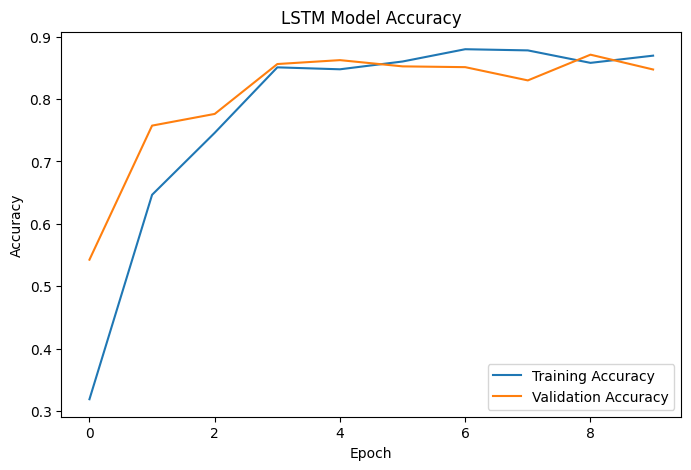

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LSTM Model Accuracy")
plt.legend()
plt.show()

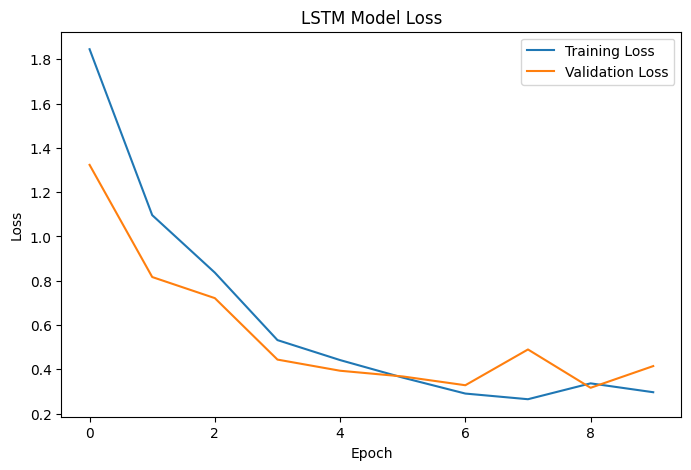

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM Model Loss")
plt.legend()
plt.show()

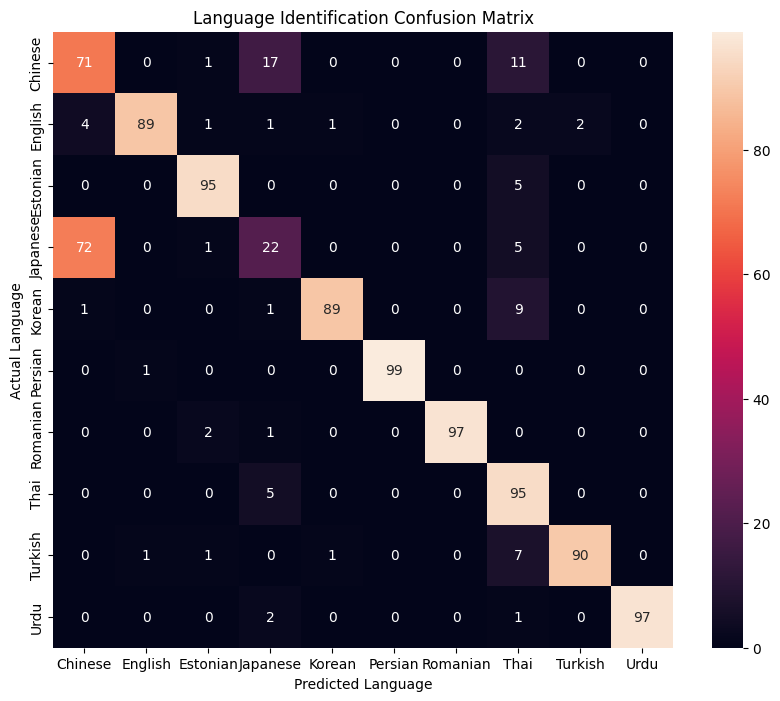

In [20]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Language")
plt.ylabel("Actual Language")
plt.title("Language Identification Confusion Matrix")
plt.show()

In [21]:
def predict_language(text):
    text = clean_text(text)

    sequence = tokenizer.texts_to_sequences([text])

    padded = pad_sequences(
        sequence,
        maxlen=max_length,
        padding="post",
        truncating="post"
    )

    probabilities = model.predict(padded, verbose=0)[0]

    index = np.argmax(probabilities)

    language = label_encoder.inverse_transform([index])[0]

    print("Input:", text)
    print("Predicted language:", language)
    print("Confidence:", round(float(probabilities[index]) * 100, 2), "%")

In [43]:
predict_language("tamil, how are you?")
predict_language("Hola, como estas?")
predict_language("Guten Morgen")

Input: tamil, how are you?
Predicted language: Japanese
Confidence: 21.27 %
Input: hola, como estas?
Predicted language: Japanese
Confidence: 50.51 %
Input: guten morgen
Predicted language: Chinese
Confidence: 48.88 %


In [44]:
print(label_encoder.classes_)

['Chinese' 'English' 'Estonian' 'Japanese' 'Korean' 'Persian' 'Romanian'
 'Thai' 'Turkish' 'Urdu']


In [45]:
print(df["language"].value_counts())

language
Chinese     500
English     500
Estonian    500
Japanese    500
Korean      500
Persian     500
Romanian    500
Thai        500
Turkish     500
Urdu        500
Name: count, dtype: int64


In [46]:
for i in range(5):
    print("Actual:", label_encoder.inverse_transform([y_test[i]])[0])
    predict_language(X_test[i])
    print()

Actual: Urdu
Input: انگور ایک پودے اور اسکے پھل کا نام ہے۔ یہ پودا بیل کی صورت میں اگتا ہے اور اسکا پھل گچھوں میں اگتا ہے۔ ایک گھچے میں سے لے کر انگور کے دانے اگ سکتے ہیں۔ انھیں اس حالت میں بھی کھایا جاسکتا ہے یا پھر اس سے جام جوس جیلی شراب اور انگور کے بیجوں کا تیل بھی بنایا جا سکتا ہے۔ انگور جب سوکھ جاتے ہیں تو ان سے کشمش بھی بنائی جاتی ہے۔ پاکستان کے صوبہ خیبر پختونخوا کے ضلع چترال کی وادی کالاش میں انگور سے دیسی شراب بھی بنایی جاتی ہے-
Predicted language: Urdu
Confidence: 98.98 %

Actual: Romanian
Input: pierzându-și autonomia jurisdicțională în abația a traversat o lungă perioadă de declin atât economic cât și spiritual care s-a încheiat cu desființarea mănăstirii în biserica a menținut o scurtă perioadă rolul de parohie dar a fost închisă în în timpul ocupării orașului de către armatele franceze ale lui napoleon jurisdicția ei canonică fiind transferată bisericii santa maria del rosario denumită popular gesuati
Predicted language: Romanian
Confidence: 98.94 %

Actual: Estonian
In

In [48]:
model.save("language_lstm.keras")

In [24]:
import pickle

with open("tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

with open("label_encoder.pkl", "wb") as f:
    pickle.dump(label_encoder, f)

In [25]:
from google.colab import files

files.download("language_lstm.keras")
files.download("tokenizer.pkl")
files.download("label_encoder.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:
predict_language("Bonjour, comment allez-vous?")
predict_language("Hola, como estas?")
predict_language("Guten Morgen")

Input: bonjour, comment allez-vous?
Predicted language: Japanese
Confidence: 52.89 %
Input: hola, como estas?
Predicted language: Japanese
Confidence: 50.51 %
Input: guten morgen
Predicted language: Chinese
Confidence: 48.88 %


In [33]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
recall = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [
        accuracy,
        precision,
        recall,
        f1
    ]
})

results.to_csv("evaluation_results.csv", index=False)

print(results)

      Metric     Score
0   Accuracy  0.844000
1  Precision  0.850731
2     Recall  0.844000
3   F1-score  0.838756


In [34]:
import pandas as pd
from google.colab import files

results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [accuracy, precision, recall, f1]
})

results.to_csv("evaluation_results.csv", index=False)

print(results)

files.download("evaluation_results.csv")

      Metric     Score
0   Accuracy  0.844000
1  Precision  0.850731
2     Recall  0.844000
3   F1-score  0.838756


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

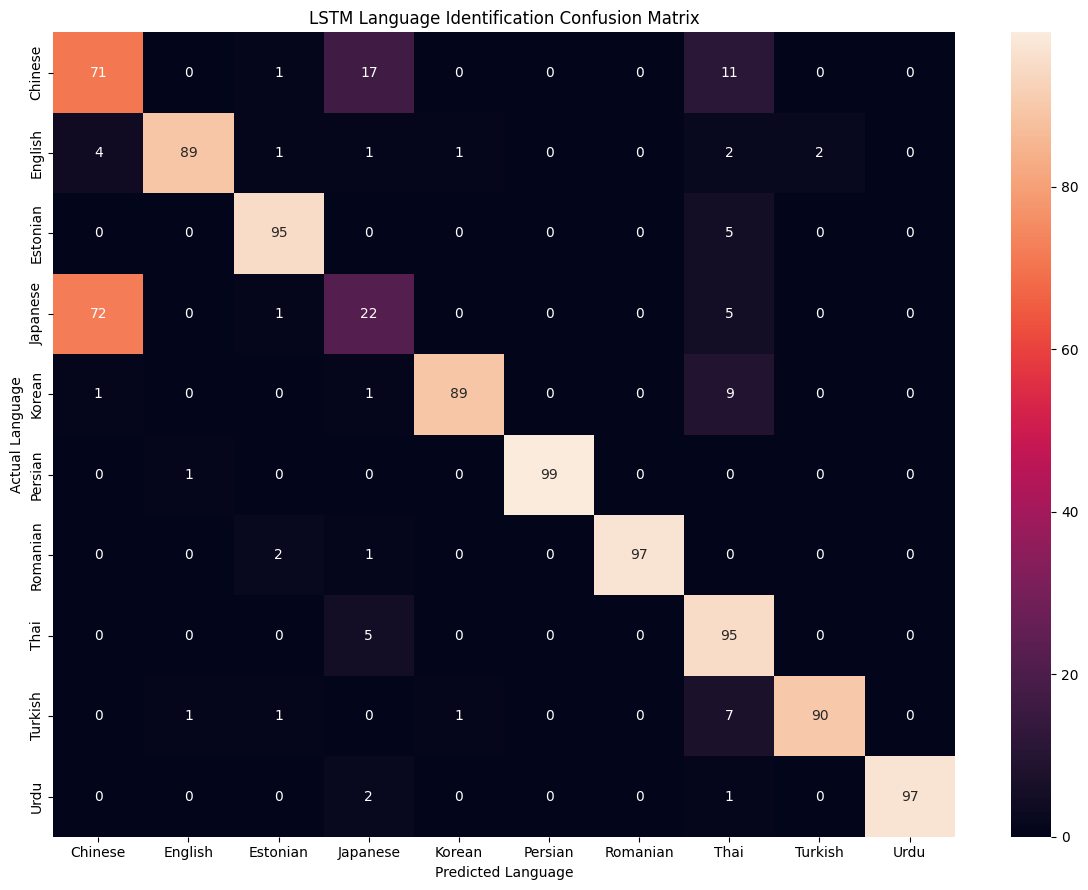

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Language")
plt.ylabel("Actual Language")
plt.title("LSTM Language Identification Confusion Matrix")
plt.tight_layout()
plt.show()

In [38]:
model.save("language_lstm.keras")

In [39]:
import pickle

with open("tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

with open("label_encoder.pkl", "wb") as f:
    pickle.dump(label_encoder, f)

In [40]:
results.to_csv("evaluation_results.csv", index=False)

In [41]:
from google.colab import files

files.download("language_lstm.keras")
files.download("tokenizer.pkl")
files.download("label_encoder.pkl")
files.download("evaluation_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [51]:
model.save("language_lstm.keras")